# Geometry-only clustering review

This notebook does not select a winner automatically. A clustering result is first screened for minimum cluster size and cross-example support; supported candidates are then compared through several metrics, stability, and physical interpretation.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'RAPID').exists():
    REPO_ROOT = REPO_ROOT.parents[1]
OUTPUT_ROOT = Path('/Volumes/PhD/river_hierarchy/network_variants/output')
EXAMPLE_IDS = ['02', '03', '05', '11', '13', '15', '21', '56']
RUN_DIR = REPO_ROOT / 'RAPID' / 'classification' / 'results' / f"clustering-review-{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"


In [2]:
command = [sys.executable, str(REPO_ROOT / 'RAPID/classification/train_rapid_geometry_clustering.py'),
           '--output-root', str(OUTPUT_ROOT), '--results-dir', str(RUN_DIR),
           '--example-ids', *EXAMPLE_IDS]
subprocess.run(command, cwd=REPO_ROOT, check=True)


Wrote /Users/6256481/Code/river-hierarchy/RAPID/classification/results/clustering-review-20260824T135325Z
Wrote a clustering review table; inspect supported candidates rather than treating any single metric as a winner.


CompletedProcess(args=['/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python', '/Users/6256481/Code/river-hierarchy/RAPID/classification/train_rapid_geometry_clustering.py', '--output-root', '/Volumes/PhD/river_hierarchy/network_variants/output', '--results-dir', '/Users/6256481/Code/river-hierarchy/RAPID/classification/results/clustering-review-20260824T135325Z', '--example-ids', '02', '03', '05', '11', '13', '15', '21', '56'], returncode=0)

In [3]:
summary = pd.read_csv(RUN_DIR / 'clustering_quality_summary.csv')
regular = summary.loc[summary.valid_exploratory_solution].copy()
outliers = summary.loc[summary.outlier_candidate].copy()
unsupported = summary.loc[~summary.valid_exploratory_solution & ~summary.outlier_candidate].copy()
print('Regular-structure candidates:')
display(regular)
print('Outlier candidates — inspect separately; they are not automatically rejected or treated as regular classes:')
display(outliers)
print('Unsupported partitions:')
display(unsupported)


Regular-structure candidates:


,algorithm,n_clusters,noise_fraction,smallest_cluster_size,min_cluster_example_support,valid_exploratory_solution,outlier_candidate,silhouette,calinski_harabasz,davies_bouldin,posthoc_response_mean_range_pct_points,review_status
0,agglomerative_ward_k2,2,0.0,37,7,True,False,0.454432,94.199283,0.880732,0.188178,regular-structure candidate — inspect stabilit...
1,kmeans_k2,2,0.0,35,6,True,False,0.463383,94.525926,0.843025,0.197462,regular-structure candidate — inspect stabilit...


Outlier candidates — inspect separately; they are not automatically rejected or treated as regular classes:


,algorithm,n_clusters,noise_fraction,smallest_cluster_size,min_cluster_example_support,valid_exploratory_solution,outlier_candidate,silhouette,calinski_harabasz,davies_bouldin,posthoc_response_mean_range_pct_points,review_status
3,agglomerative_average_k3,3,0.0,1,1,False,True,0.572179,90.632132,0.481790,2.637852,outlier candidate — validate its geometry and ...
4,agglomerative_average_k4,4,0.0,1,1,False,True,0.507524,63.095338,0.458237,2.923636,outlier candidate — validate its geometry and ...
5,agglomerative_average_k5,5,0.0,1,1,False,True,0.500133,110.421923,0.541970,2.923636,outlier candidate — validate its geometry and ...
6,agglomerative_average_k6,6,0.0,1,1,False,True,0.480739,91.947782,0.619635,3.873516,outlier candidate — validate its geometry and ...
7,agglomerative_ward_k3,3,0.0,1,1,False,True,0.465782,118.733603,0.605476,0.188698,outlier candidate — validate its geometry and ...
8,agglomerative_ward_k4,4,0.0,1,1,False,True,0.422831,152.411618,0.669084,0.374395,outlier candidate — validate its geometry and ...
9,agglomerative_ward_k5,5,0.0,1,1,False,True,0.529805,205.734373,0.729663,0.577226,outlier candidate — validate its geometry and ...
10,agglomerative_ward_k6,6,0.0,1,1,False,True,0.588551,327.241414,0.604567,1.967095,outlier candidate — validate its geometry and ...
15,gmm_full_k3,3,0.0,1,1,False,True,0.344930,108.510274,0.712418,0.317121,outlier candidate — validate its geometry and ...
16,gmm_full_k4,4,0.0,1,1,False,True,0.411816,146.189088,0.698156,0.382416,outlier candidate — validate its geometry and ...


Unsupported partitions:


,algorithm,n_clusters,noise_fraction,smallest_cluster_size,min_cluster_example_support,valid_exploratory_solution,outlier_candidate,silhouette,calinski_harabasz,davies_bouldin,posthoc_response_mean_range_pct_points,review_status
2,agglomerative_average_k2,2,0.000000,1,1,False,False,0.865565,84.145278,0.097198,0.145839,unsupported partition — insufficient cluster s...
11,dbscan_q50,9,0.346479,3,1,False,False,0.708040,703.188123,0.546142,0.806058,unsupported density partition — excessive nois...
12,dbscan_q70,6,0.194366,5,1,False,False,0.421930,155.862675,0.724770,0.950013,unsupported partition — insufficient cluster s...
13,dbscan_q85,7,0.081690,5,1,False,False,0.515151,160.151796,0.620086,1.154206,unsupported partition — insufficient cluster s...
14,gmm_full_k2,2,0.000000,1,1,False,False,0.865565,84.145278,0.097198,0.145839,unsupported partition — insufficient cluster s...
23,optics,21,0.507042,5,1,False,False,0.645167,419.207646,0.416328,3.914474,unsupported density partition — excessive nois...
24,spectral_k2,2,0.000000,102,1,False,False,0.345443,82.962006,1.055453,0.328475,unsupported partition — insufficient cluster s...
25,spectral_k3,3,0.000000,52,1,False,False,0.302272,63.492184,1.095437,0.410200,unsupported partition — insufficient cluster s...
26,spectral_k4,4,0.000000,37,1,False,False,0.399425,94.468299,0.916299,0.487960,unsupported partition — insufficient cluster s...
27,spectral_k5,5,0.000000,37,1,False,False,0.397669,84.329827,1.268295,0.579149,unsupported partition — insufficient cluster s...


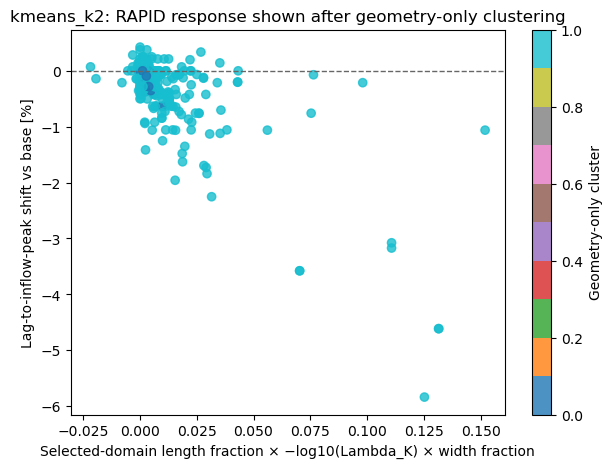

,n,examples,response_mean,response_median
cluster,,,,
0,35,6,-0.108977,0.000000
1,320,8,-0.306439,-0.070771


In [4]:
ALGORITHM_TO_INSPECT = 'kmeans_k2'  # select a candidate from the tables above
assignments = pd.read_csv(RUN_DIR / 'cluster_assignments.csv')
plot_df = assignments.loc[assignments.algorithm.eq(ALGORITHM_TO_INSPECT)].copy()
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(plot_df.len_fraction_width_weighted_log_lambda, plot_df.lag_to_inflow_peak_pct_shift_vs_base, c=plot_df.cluster, cmap='tab10', alpha=.8)
ax.axhline(0, color='0.4', linewidth=1, linestyle='--')
ax.set(xlabel='Selected-domain length fraction × −log10(Lambda_K) × width fraction', ylabel='Lag-to-inflow-peak shift vs base [%]', title=f'{ALGORITHM_TO_INSPECT}: RAPID response shown after geometry-only clustering')
fig.colorbar(scatter, ax=ax, label='Geometry-only cluster')
plt.show()
display(plot_df.groupby('cluster').agg(n=('state_id','size'), examples=('example_id','nunique'), response_mean=('lag_to_inflow_peak_pct_shift_vs_base','mean'), response_median=('lag_to_inflow_peak_pct_shift_vs_base','median')))
